# H3 Training Record — Proposal-Supply Localizer

**Experiment:** `h3_kub_localizer_sigma_adaptive_sizeaware_seed42_clean_v3`

**Notebook role:** authoritative post-training research record for the H3
proposal-supply localizer run. This notebook reads persisted artifacts only. It
trains nothing, runs no model inference, performs no H3 supply-axis evaluation,
performs no downstream regional-refiner evaluation, accesses no TEST data, and
starts no Phase 15.

**Provenance chain:** final pretraining binding -> launch-safety binding -> live
training record -> authoritative training closure -> disk-only checkpoint-selection
replay. The closure and replay artifacts are the authority for every final value
shown here; this notebook recomputes only display derivatives and verification
checks, and it displays the replay verdict exactly as recorded in the replay
artifact (nothing is hardcoded to PASS).

This is **POST-PHASE14 work**. It is **not Phase 15**. Phase 15 remains
`NOT_STARTED_AND_NOT_AUTHORIZED`. TEST remains `CLOSED`.

In [1]:
from pathlib import Path
import ast
import hashlib
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def discover_repo(start=None):
    candidates = []
    if start is not None:
        candidates.append(Path(start).resolve())
    candidates.extend([Path.cwd().resolve(), Path.cwd().resolve().parent])
    try:
        candidates.append(Path(__file__).resolve())
    except NameError:
        pass
    for candidate in candidates:
        current = candidate if candidate.is_dir() else candidate.parent
        for root in (current, *current.parents):
            if all((root / name).is_dir() for name in ("scripts", "reports", "manifests", "notebooks")):
                return root
    fallback = Path(r"D:/Softfors/jup")
    if all((fallback / name).is_dir() for name in ("scripts", "reports", "manifests", "notebooks")):
        return fallback
    raise RuntimeError("Repository root not found: expected scripts/, reports/, manifests/, notebooks/.")

ROOT = discover_repo()
EXP = ROOT / "experiments" / "h3_kub_localizer_sigma_adaptive_sizeaware_seed42_clean_v3"
CHK = ROOT / "checkpoints" / "h3_kub_localizer_sigma_adaptive_sizeaware_seed42_clean_v3"
AUDITS = ROOT / "reports" / "audits"
TABLES = ROOT / "reports" / "tables"

def load_json(relative):
    with (ROOT / relative).open("r", encoding="utf-8") as handle:
        return json.load(handle)

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()

def literal(value):
    return ast.literal_eval(value) if isinstance(value, str) else value

PREBIND_REL = "reports/audits/h3_proposal_supply_final_pretraining_binding_v2.json"
LAUNCH_REL = "reports/audits/h3_training_launch_binding.json"
CLOSURE_REL = "reports/audits/h3_proposal_supply_training_closure.json"
REPLAY_REL = "reports/audits/h3_checkpoint_selection_replay.json"
HISTORY_REL = "experiments/h3_kub_localizer_sigma_adaptive_sizeaware_seed42_clean_v3/history.csv"

required = [PREBIND_REL, LAUNCH_REL, CLOSURE_REL, REPLAY_REL, HISTORY_REL]
missing = [rel for rel in required if not (ROOT / rel).exists()]
if missing:
    raise RuntimeError("H3 training-record artifacts missing (closure/replay must exist before this notebook runs): " + "; ".join(missing))

PREBIND = load_json(PREBIND_REL)
LAUNCH = load_json(LAUNCH_REL)
CLOSURE = load_json(CLOSURE_REL)
REPLAY = load_json(REPLAY_REL)
hist = pd.read_csv(ROOT / HISTORY_REL)

print("Repository root:", ROOT)
print("Governance: no training, no inference, no supply-axis evaluation, no TEST access, no Phase 15.")
print("History rows:", len(hist))
print("Training closure status:", CLOSURE["status"])
print("Checkpoint replay verdict (from artifact):", REPLAY["verdict"])

Repository root: D:\Softfors\jup
Governance: no training, no inference, no supply-axis evaluation, no TEST access, no Phase 15.
History rows: 69
Training closure status: H3_TRAINING_COMPLETE__CHECKPOINT_SELECTION_REPLAY_PASS__SUPPLY_EVALUATION_PENDING
Checkpoint replay verdict (from artifact): H3_CHECKPOINT_SELECTION_REPLAY_PASS


## 1. H3 scientific question

Phase 14 root-cause diagnostics classified the localizer bottleneck as
`F_MIXED_BOTTLENECK`, and the axis-priority diagnostic established
`H3_DESIGN_ELIGIBLE__AXIS_PROPOSAL_SUPPLY_RECALL`:

- **Axis:** `A_PROPOSAL_SUPPLY_RECALL_LIMITATION`
- **Intervention family:** `A_TARGET_SUPPORT_REDESIGN`
- **Question:** does a size-adaptive Gaussian target support (sigma scaled by each
  component's 128-space foreground area, instead of the parent's fixed
  `sigma = 0.75`) increase the localizer's proposal supply — in particular the
  recall of decoded proposals over canonical VAL components at the frozen decode
  (threshold 0.10 / margin 0.20 / top_k 5 / NMS IoU 0.30) — under otherwise
  parent-identical training?

This notebook records the TRAINING side only. Whether the intervention actually
improves proposal-supply recall is decided by the separate, not-yet-authorized
supply-axis evaluation (notebook 05) and formal adjudication (notebook 06).

## 2. Why a new localizer training run was required

The intervention changes the TRAINING TARGETS themselves: the Gaussian heatmap
support around each component centroid becomes component-size dependent. Target
support is a learned-signal property, not an inference-time parameter, so the
existing Phase-13B parent localizer (trained with fixed `sigma = 0.75`) cannot be
re-decoded under the new support — the weights must be retrained against the new
targets.

To isolate the target-support variable, H3 retrains a parent-identical
`KUBLocalizer` (base_channels 16, 512 -> 128 heatmap) from RANDOM initialization
with the parent-identical loss (CenterNetFocalLoss alpha 2.0 / beta 4.0 /
dice_weight 0.0), optimizer (AdamW lr 1e-4 / wd 1e-4), scheduler
(CosineAnnealingLR T_max 100), seed (42), and canonical TRAIN/VAL populations.
Only the target-support formula differs from the parent run.

## 3. Frozen H3 intervention

```text
sigma_i = clip(0.35 + 0.40 * sqrt(A128_i / A_ref), 0.35, 0.75)
A_ref   = 13.0   (p75 of per-component 128-space foreground areas over the
                  canonical clean-v3 TRAIN FULL_FIELD population, 770 images /
                  1161 components, via the exact H3 runtime centroid->128-space
                  mapping; no combined-mask relabeling)
```

- Zero-area components take the floor `sigma = 0.35` deterministically.
- Calibration non-degeneracy: 14 distinct sigma levels; 25.5% at the 0.75 ceiling;
  4.5% at the 0.35 floor; TINY median sigma 0.461 < non-TINY median 0.644.
- Superseded cardinality-violating calibrations (A_ref 14.0 and 12.0, both from
  relabeled component sets) are NOT used.
- Proposal decoding is frozen to exactly ONE configuration per epoch:
  threshold 0.10, margin 0.20, top_k 5, NMS IoU 0.30. Grid search is DISABLED.
- Checkpoint selection is frozen to the 2-term strict lexicographic tuple
  `(val_localization_recall, -val_loss)`; an exact tie is NOT an improvement.

## 4. Final authoritative pretraining binding (design era)

In [2]:
display(pd.DataFrame([
    ("artifact", PREBIND["artifact"]),
    ("final status", PREBIND["final_status"]),
    ("axis", PREBIND["axis"]),
    ("intervention family", PREBIND["intervention_family"]),
    ("corrected mapping", PREBIND["corrected_mapping"]),
    ("authoritative A_ref", str(PREBIND["authoritative_a_ref"])),
    ("A_ref definition", PREBIND["a_ref_definition"]),
    ("generated_utc", PREBIND["generated_utc"]),
    ("binding file SHA-256", sha256_file(ROOT / PREBIND_REL)),
], columns=["field", "value"]))

impl = pd.DataFrame(sorted(PREBIND["implementation_sha256"].items()),
                    columns=["implementation path (design-era freeze)", "SHA-256"])
display(impl)
print("The design-era dataset-module SHA differs from the launch binding: the dataset module")
print("was revised between the design freeze and the pre-launch safety check. The LAUNCH")
print("binding (section 7) is the authoritative run-era reference; current disk matches it.")
print("heatmap_targets, selection helper, and config are byte-identical across both bindings.")

,field,value
0,artifact,H3_PROPOSAL_SUPPLY_FINAL_PRETRAINING_BINDING_V2
1,final status,H3_FINAL_PRETRAINING_BINDING_COMPLETE__AWAITIN...
2,axis,A_PROPOSAL_SUPPLY_RECALL_LIMITATION
3,intervention family,A_TARGET_SUPPORT_REDESIGN
4,corrected mapping,sigma_i = clip(0.35 + 0.40 * sqrt(A128_i / A_r...
5,authoritative A_ref,13.0
6,A_ref definition,p75 of per-component 128-space foreground area...
7,generated_utc,2026-09-23T15:49:51Z
8,binding file SHA-256,ff10d13bd151d48f3d1c6ce2528a26b0a4fe16c8f97e37...


,implementation path (design-era freeze),SHA-256
0,configs/kub/phase13b_localizer_h3_size_adaptiv...,320a367068b6bec4ea357ebea4bca1460db2c7f7a435f1...
1,scripts/audit/h3_calibrate_size_adaptive_sigma...,6c3eb477db3d74d75aa14b7182b11d6113204b58bbfb93...
2,scripts/training/train_phase13b_localizer.py,37b64310d38222310ce060803e37d17e4b6916ce7c522d...
3,src/data/kub_localizer_dataset.py,b1c4645f8860d557ffc6cb145c224a7ddb5d804e558147...
4,src/inference/heatmap_targets.py,4fe01377b5fb2f15377fda37ef2114a04185fa44a6dace...
5,src/training/clean_v3_selection.py,807a70181c1f0da7481a26f1d06e1a1f2ca21dd0e93d44...
6,tests/test_h3_size_adaptive_sigma.py,57094021876284e14449804f0a70ca5cfe62062612a5de...


The design-era dataset-module SHA differs from the launch binding: the dataset module
was revised between the design freeze and the pre-launch safety check. The LAUNCH
binding (section 7) is the authoritative run-era reference; current disk matches it.
heatmap_targets, selection helper, and config are byte-identical across both bindings.


## 5. Canonical TRAIN / VAL population

In [3]:
tp = CLOSURE["train_population"]
vp = CLOSURE["val_population"]
component_audit = pd.read_csv(TABLES / "h3_v2_component_area_audit.csv")

population = pd.DataFrame([
    ("TRAIN images", tp["images"], "training closure"),
    ("TRAIN canonical components", tp["canonical_components"], "training closure"),
    ("TRAIN components (component-area audit rows)", len(component_audit), "reports/tables/h3_v2_component_area_audit.csv (notebook recomputation)"),
    ("TRAIN orphan sample excluded", tp.get("orphan_sample_id", "ef36ad8332b2f33882dc668a5b6846e5"), "training closure"),
    ("VAL images", vp["images"], "training closure"),
    ("VAL canonical components", vp["canonical_components"], "training closure"),
    ("VAL TINY components", vp["tiny_components"], "training closure"),
    ("VAL components per epoch (history.csv total_gt_components)", sorted(hist["total_gt_components"].unique().tolist()), "notebook recomputation from history.csv"),
], columns=["population fact", "value", "source"])
display(population)
print("Manifest files (full split records, not per-run filters): train.csv rows =",
      len(pd.read_csv(ROOT / "manifests/phase4_v3/train.csv")),
      "; val.csv rows =", len(pd.read_csv(ROOT / "manifests/phase4_v3/val.csv")))
print("The canonical 770/1161 TRAIN and 103/152 VAL populations are defined by the")
print("manifest-filtered clean-v3 canonical loader used at training time; the closure and")
print("binding recorded them, and history.csv independently confirms 152 VAL components")
print("at every epoch.")

,population fact,value,source
0,TRAIN images,770,training closure
1,TRAIN canonical components,1161,training closure
2,TRAIN components (component-area audit rows),1161,reports/tables/h3_v2_component_area_audit.csv ...
3,TRAIN orphan sample excluded,ef36ad8332b2f33882dc668a5b6846e5,training closure
4,VAL images,103,training closure
5,VAL canonical components,152,training closure
6,VAL TINY components,72,training closure
7,VAL components per epoch (history.csv total_gt...,[152],notebook recomputation from history.csv


Manifest files (full split records, not per-run filters): train.csv rows = 5832 ; val.csv rows = 808
The canonical 770/1161 TRAIN and 103/152 VAL populations are defined by the
manifest-filtered clean-v3 canonical loader used at training time; the closure and
binding recorded them, and history.csv independently confirms 152 VAL components
at every epoch.


## 6. Complete training configuration

In [4]:
sc = LAUNCH["scientific_config"]
cfg = pd.DataFrame([
    ("experiment_id", CLOSURE["experiment_id"], "launch binding / closure"),
    ("seed", sc["seed"], "launch binding"),
    ("model architecture", CLOSURE["model"]["architecture"] + " (factory " + CLOSURE["model"]["factory"] + ")", "closure"),
    ("model channels", "in=1, out=1, base_channels=16", "closure"),
    ("resolution", str(sc["resolution"]) + " px, heatmap " + str(sc["heatmap_resolution"]) + " px", "launch binding"),
    ("initialization", CLOSURE["model"]["initialization"], "closure"),
    ("size_adaptive_sigma", str(sc["size_adaptive_sigma"]), "launch binding"),
    ("sigma formula", CLOSURE["target_support"]["formula"], "closure"),
    ("A_ref", str(sc["A_ref"]), "launch binding"),
    ("sigma bounds", str(sc["sigma_min"]) + " .. " + str(sc["sigma_max"]), "launch binding"),
    ("loss", sc["loss"], "launch binding"),
    ("optimizer", sc["optimizer"], "launch binding"),
    ("scheduler", sc["scheduler"], "launch binding"),
    ("max_epochs", str(sc["max_epochs"]), "launch binding"),
    ("patience (early stopping)", str(sc["patience"]), "launch binding"),
    ("proposal decode (frozen)", json.dumps(sc.get("decode", CLOSURE["proposal_decode"])), "launch binding / closure"),
    ("proposal configurations per epoch", str(sc["proposal_configurations_evaluated_per_epoch"]), "launch binding"),
    ("grid search", "enabled=" + str(sc["grid_search_enabled"]), "launch binding"),
    ("selection rule", LAUNCH["selection_tuple"]["rule"] + " over tuple " + json.dumps(LAUNCH["selection_tuple"]["terms"]), "launch binding"),
], columns=["configuration field", "value", "source"])
display(cfg)

,configuration field,value,source
0,experiment_id,h3_kub_localizer_sigma_adaptive_sizeaware_seed...,launch binding / closure
1,seed,42,launch binding
2,model architecture,compact_unet_heatmap (factory kub_localizer),closure
3,model channels,"in=1, out=1, base_channels=16",closure
4,resolution,"512 px, heatmap 128 px",launch binding
5,initialization,random (no pretrained weights),closure
6,size_adaptive_sigma,True,launch binding
7,sigma formula,sigma_i = clip(0.35 + 0.40 * sqrt(A128_i / A_r...,closure
8,A_ref,13.0,launch binding
9,sigma bounds,0.35 .. 0.75,launch binding


## 7. Launch-safety binding

In [5]:
display(pd.DataFrame([
    ("status", LAUNCH["status"]),
    ("written_before_epoch_1", str(LAUNCH["written_before_epoch_1"])),
    ("timestamp_utc", LAUNCH["timestamp_utc"]),
    ("classification", LAUNCH["classification"]),
    ("scientific axis", LAUNCH["scientific_axis"]),
    ("checkpoint namespace", LAUNCH["checkpoint_namespace"]),
    ("exact training command", LAUNCH["exact_training_command"]),
    ("binding file SHA-256", sha256_file(ROOT / LAUNCH_REL)),
], columns=["field", "value"]))

display(pd.DataFrame(sorted(LAUNCH["final_shas"].items()),
                     columns=["run-era component (launch binding)", "SHA-256"]))
print("Current-disk verification of these run-era SHAs is recorded in the training closure")
print("(scientific_module_shas_match_launch_binding) and re-verified in the provenance table below.")

,field,value
0,status,H3_TRAINING_PROSPECTIVELY_AUTHORIZED__READY_TO...
1,written_before_epoch_1,True
2,timestamp_utc,2026-09-25T06:03:40.835284+00:00
3,classification,OPERATIONAL_OUTPUT_ISOLATION__NO_SCIENTIFIC_AX...
4,scientific axis,A_PROPOSAL_SUPPLY_RECALL_LIMITATION / A_TARGET...
5,checkpoint namespace,checkpoints/h3_kub_localizer_sigma_adaptive_si...
6,exact training command,python scripts/training/train_phase13b_localiz...
7,binding file SHA-256,49046f31f6a766d485a761c8827bd3ca70a400f4779b17...


,run-era component (launch binding),SHA-256
0,checkpointing_module,08366f72f3141e5d18f008981465f5e9138c0b51336fd6...
1,config,320a367068b6bec4ea357ebea4bca1460db2c7f7a435f1...
2,dataset_module,77aba36b0ba65b951c49a5caf2e1abcdc2092ca0cd3e2d...
3,selection_module,807a70181c1f0da7481a26f1d06e1a1f2ca21dd0e93d44...
4,train_manifest,28702fc3a5ff8b950db372f03232d335e3a30b1fc2f21d...
5,trainer,9099d6de339aba43d5e92284ea741568f16c7f5c39e7c1...
6,val_manifest,082c80b2bda63fd73f371f109c34643adf01edaead9216...


Current-disk verification of these run-era SHAs is recorded in the training closure
(scientific_module_shas_match_launch_binding) and re-verified in the provenance table below.


## 8. COMPLETE per-epoch training history

Every completed H3 epoch is displayed below — no head/tail truncation. All
`history.csv` columns are trainer-recorded authoritative values. Columns with the
`derived_` prefix are notebook-computed DISPLAY-ONLY derivatives (from the replay
artifact's per-epoch selection replay and the closure's per-epoch trainer-producer
map); they never replace trainer-recorded values.

In [6]:
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 260)

replay_rows = {int(r["epoch"]): r for r in REPLAY["per_epoch_replay"]}
producer = {int(k): v for k, v in CLOSURE["implementation_shas"]["trainer_per_epoch_producer"].items()}

epoch_table = hist.copy()
epoch_table["derived_best_epoch_so_far"] = [replay_rows[e]["best_epoch_so_far"] for e in epoch_table["epoch"]]
epoch_table["derived_best_val_localization_recall_so_far"] = epoch_table["val_localization_recall"].cummax()
epoch_table["derived_epochs_since_best"] = epoch_table["epoch"] - epoch_table["derived_best_epoch_so_far"]
epoch_table["derived_is_new_best"] = [replay_rows[e]["is_new_best"] for e in epoch_table["epoch"]]
epoch_table["derived_bad_epochs"] = [replay_rows[e]["bad_epochs"] for e in epoch_table["epoch"]]
epoch_table["derived_trainer_revision"] = [producer[e][:12] for e in epoch_table["epoch"]]

trainer_recorded_columns = list(hist.columns)
derived_columns = [c for c in epoch_table.columns if c.startswith("derived_")]
view = epoch_table[trainer_recorded_columns + derived_columns].copy()
numeric = view.select_dtypes(include="number").columns
view[numeric] = view[numeric].round(6)
print("Trainer-recorded columns:", len(trainer_recorded_columns), "| derived display columns:", len(derived_columns))
print("Epochs displayed:", len(view), "(complete; no truncation)")
display(view)

Trainer-recorded columns:

 31 | derived display columns: 6
Epochs displayed: 69 (complete; no truncation)


,epoch,train_loss,val_loss,val_hard_tiny_recovered90,val_global_empty_images_covered90,val_tiny_recall90,val_overall_recall90,learning_rate,epoch_seconds,peak_gpu_allocated,peak_gpu_reserved,feasible_config_count,localization_status,mean_roi_area_fraction,mean_proposals_per_image,mean_max_heatmap,median_max_heatmap,fixed_decode,val_localization_recall,per_size_recall90,any_overlap_recall,coverage50_recall,mean_coverage,zero_proposal_gt,zero_proposal_tiny,total_gt_components,total_proposals,precision,background_fraction,selection_tuple,selection_term_names,derived_best_epoch_so_far,derived_best_val_localization_recall_so_far,derived_epochs_since_best,derived_is_new_best,derived_bad_epochs,derived_trainer_revision
0,1,12.450440,10.375061,0,0,0.000000,0.000000,0.000100,329.295846,755587072,905969664,1,FEASIBLE,0.000000,0.000000,0.095687,0.095886,"{'threshold': 0.1, 'margin': 0.2, 'top_k': 5, ...",0.000000,"{'TINY': 0.0, 'SMALL': 0.0, 'MEDIUM': 0.0, 'LA...",0.000000,0.000000,0.000000,152,72,152,0,0.000000,0.000000,"[0.0, -10.375060668358437]","['val_localization_recall', 'negative_val_loss']",1,0.000000,0,True,0,9099d6de339a
1,2,8.800665,7.605725,0,0,0.000000,0.000000,0.000100,298.833728,755587072,905969664,1,FEASIBLE,0.000000,0.000000,0.094057,0.094177,"{'threshold': 0.1, 'margin': 0.2, 'top_k': 5, ...",0.000000,"{'TINY': 0.0, 'SMALL': 0.0, 'MEDIUM': 0.0, 'LA...",0.000000,0.000000,0.000000,152,72,152,0,0.000000,0.000000,"[0.0, -7.605725086652315]","['val_localization_recall', 'negative_val_loss']",2,0.000000,0,True,0,9099d6de339a
2,3,6.564535,5.793779,0,0,0.000000,0.000000,0.000100,303.641072,757520384,910163968,1,FEASIBLE,0.000000,0.000000,0.096484,0.096558,"{'threshold': 0.1, 'margin': 0.2, 'top_k': 5, ...",0.000000,"{'TINY': 0.0, 'SMALL': 0.0, 'MEDIUM': 0.0, 'LA...",0.000000,0.000000,0.000000,152,72,152,0,0.000000,0.000000,"[0.0, -5.793779391508836]","['val_localization_recall', 'negative_val_loss']",3,0.000000,0,True,0,45bef74f4edd
3,4,5.235439,4.825482,0,0,0.000000,0.000000,0.000100,309.849597,757520384,910163968,1,FEASIBLE,0.000000,0.000000,0.095621,0.095703,"{'threshold': 0.1, 'margin': 0.2, 'top_k': 5, ...",0.000000,"{'TINY': 0.0, 'SMALL': 0.0, 'MEDIUM': 0.0, 'LA...",0.000000,0.000000,0.000000,152,72,152,0,0.000000,0.000000,"[0.0, -4.8254818091025715]","['val_localization_recall', 'negative_val_loss']",4,0.000000,0,True,0,45bef74f4edd
4,5,4.406889,4.063768,0,0,0.000000,0.000000,0.000099,306.171553,757520384,910163968,1,FEASIBLE,0.000000,0.000000,0.095124,0.095154,"{'threshold': 0.1, 'margin': 0.2, 'top_k': 5, ...",0.000000,"{'TINY': 0.0, 'SMALL': 0.0, 'MEDIUM': 0.0, 'LA...",0.000000,0.000000,0.000000,152,72,152,0,0.000000,0.000000,"[0.0, -4.063767946683443]","['val_localization_recall', 'negative_val_loss']",5,0.000000,0,True,0,45bef74f4edd
5,6,3.827924,3.664047,0,0,0.000000,0.000000,0.000099,293.963432,757520384,910163968,1,FEASIBLE,0.000000,0.000000,0.094636,0.094666,"{'threshold': 0.1, 'margin': 0.2, 'top_k': 5, ...",0.000000,"{'TINY': 0.0, 'SMALL': 0.0, 'MEDIUM': 0.0, 'LA...",0.000000,0.000000,0.000000,152,72,152,0,0.000000,0.000000,"[0.0, -3.6640473420803366]","['val_localization_recall', 'negative_val_loss']",6,0.000000,0,True,0,45bef74f4edd
6,7,3.467797,3.274560,0,0,0.000000,0.000000,0.000099,303.491068,757520384,910163968,1,FEASIBLE,0.000000,0.000000,0.094360,0.094360,"{'threshold': 0.1, 'margin': 0.2, 'top_k': 5, ...",0.000000,"{'TINY': 0.0, 'SMALL': 0.0, 'MEDIUM': 0.0, 'LA...",0.000000,0.000000,0.000000,152,72,152,0,0.000000,0.000000,"[0.0, -3.274559635382432]","['val_localization_recall', 'negative_val_loss']",7,0.000000,0,True,0,45bef74f4edd
7,8,3.176376,3.066108,0,0,0.000000,0.000000,0.000098,307.536604,757520384,910163968,1,FEASIBLE,0.000000,0.000000,0.093992,0.093994,"{'threshold': 0.1, 'margin': 0.2, 'top_k': 5, ...",0.000000,"{'TINY': 0.0, 'SMALL': 0.0, 'MEDIUM': 0.0, 'LA...",0.000000,0.000000,0.000000,152,72,152,0,0.000000,0.000000,"[0.0, -3.066107676579402]","['val_localization_recall', 'negative_val_lo

## 9. Training summary

In [7]:
summary = pd.DataFrame([
    ("experiment_id", CLOSURE["experiment_id"]),
    ("final training status", CLOSURE["final_training_status"]),
    ("run classification", CLOSURE["run_classification"]),
    ("total epochs", CLOSURE["total_epochs"]),
    ("final epoch", CLOSURE["final_epoch"]),
    ("stop reason", CLOSURE["stop_reason"]),
    ("max epochs reached", str(CLOSURE["max_epochs_reached"])),
    ("early stopping fired", str(CLOSURE["early_stopping_fired"])),
    ("best epoch", CLOSURE["best_epoch"]),
    ("best val_localization_recall", CLOSURE["best_val_localization_recall"]),
    ("best val_loss", CLOSURE["best_val_loss"]),
    ("best selection tuple", json.dumps(CLOSURE["best_selection_tuple"])),
    ("patience", CLOSURE["patience"]),
    ("final bad_epochs", CLOSURE["final_bad_epochs"]),
    ("seed", CLOSURE["seed"]),
    ("interruptions", len(CLOSURE["interruptions"])),
    ("resumes (same-run)", len(CLOSURE["resumes"])),
    ("duplicate runs", CLOSURE["duplicate_runs"]),
    ("registry end_time (UTC)", CLOSURE["end_state"]["registry_end_time_utc"]),
], columns=["summary field", "value"])
display(summary)

,summary field,value
0,experiment_id,h3_kub_localizer_sigma_adaptive_sizeaware_seed...
1,final training status,TRAINED
2,run classification,ONE_LOGICAL_RUN__TWO_PROCESS_SEGMENTS__SAME_RU...
3,total epochs,69
4,final epoch,69
5,stop reason,EARLY_STOPPING_PATIENCE_15_FIRED
6,max epochs reached,False
7,early stopping fired,True
8,best epoch,54
9,best val_localization_recall,0.638158


## 10. Train / validation loss curves

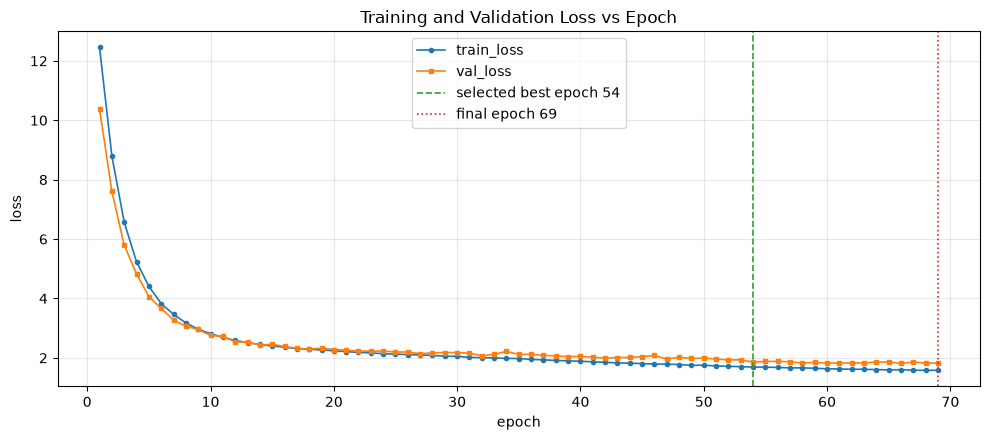

Raw recorded values only; no smoothing.


In [8]:
best_epoch = CLOSURE["best_epoch"]
final_epoch = CLOSURE["final_epoch"]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(hist["epoch"], hist["train_loss"], marker="o", markersize=3, linewidth=1.2, label="train_loss")
ax.plot(hist["epoch"], hist["val_loss"], marker="s", markersize=3, linewidth=1.2, label="val_loss")
ax.axvline(best_epoch, color="tab:green", linestyle="--", linewidth=1.2, label="selected best epoch " + str(best_epoch))
ax.axvline(final_epoch, color="tab:red", linestyle=":", linewidth=1.2, label="final epoch " + str(final_epoch))
ax.set_title("Training and Validation Loss vs Epoch")
ax.set_xlabel("epoch")
ax.set_ylabel("loss")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()
print("Raw recorded values only; no smoothing.")

## 11. VAL localization-recall curve — PRIMARY H3 training-selection figure

Raw `val_localization_recall` at the frozen decode (0.10 / 0.20 / 5 / 0.30) for
every epoch, the best-so-far envelope under the frozen selection tuple, every
new-best epoch, and the finally selected checkpoint.

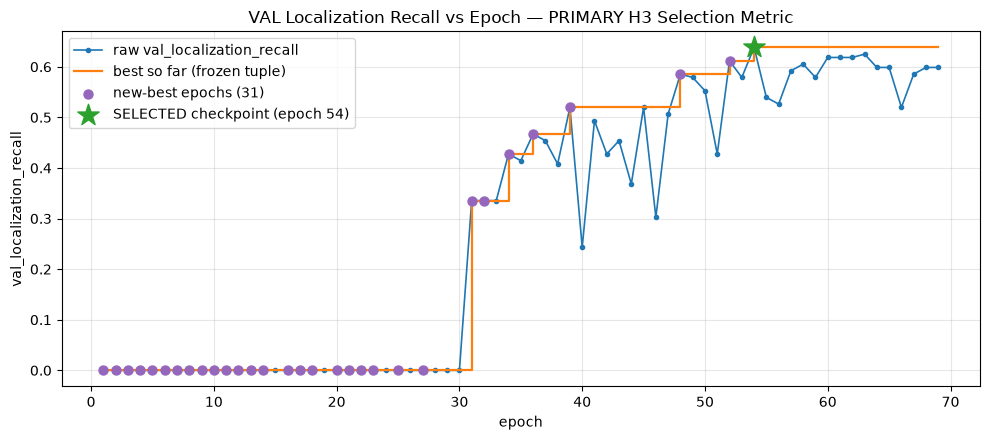

Every epoch plotted; selected checkpoint = replay-verified best under (val_localization_recall, -val_loss).


In [9]:
best_so_far = hist["val_localization_recall"].cummax()
new_best_epochs = [int(r["epoch"]) for r in REPLAY["per_epoch_replay"] if r["is_new_best"]]
new_best_recall = [float(hist.loc[hist["epoch"] == e, "val_localization_recall"].iloc[0]) for e in new_best_epochs]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(hist["epoch"], hist["val_localization_recall"], marker="o", markersize=3, linewidth=1.2, label="raw val_localization_recall")
ax.step(hist["epoch"], best_so_far, where="post", linewidth=1.6, label="best so far (frozen tuple)")
ax.scatter(new_best_epochs, new_best_recall, color="tab:purple", zorder=5, s=42, label="new-best epochs (" + str(len(new_best_epochs)) + ")")
ax.scatter([best_epoch], [float(hist.loc[hist["epoch"] == best_epoch, "val_localization_recall"].iloc[0])],
           marker="*", s=260, color="tab:green", zorder=6, label="SELECTED checkpoint (epoch " + str(best_epoch) + ")")
ax.set_title("VAL Localization Recall vs Epoch — PRIMARY H3 Selection Metric")
ax.set_xlabel("epoch")
ax.set_ylabel("val_localization_recall")
ax.legend(loc="best")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()
print("Every epoch plotted; selected checkpoint = replay-verified best under (val_localization_recall, -val_loss).")

## 12. Learning-rate curve (recorded)

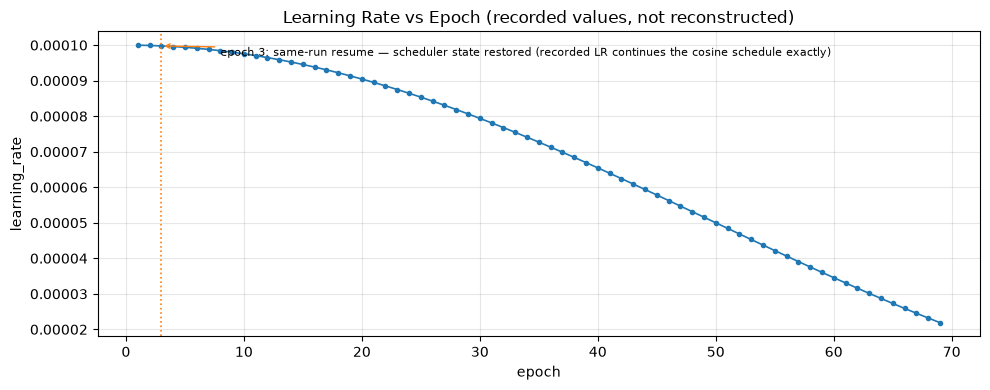

In [10]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(hist["epoch"], hist["learning_rate"], marker="o", markersize=3, linewidth=1.2)
ax.axvline(3, color="tab:orange", linestyle=":", linewidth=1.2)
ax.annotate("epoch 3: same-run resume — scheduler state restored (recorded LR continues the cosine schedule exactly)",
            xy=(3, float(hist["learning_rate"].iloc[2])), xytext=(8, float(hist["learning_rate"].max()) * 0.97),
            fontsize=8, arrowprops=dict(arrowstyle="->", color="tab:orange"))
ax.set_title("Learning Rate vs Epoch (recorded values, not reconstructed)")
ax.set_xlabel("epoch")
ax.set_ylabel("learning_rate")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## 13. Early-stopping trajectory (patience = 15)

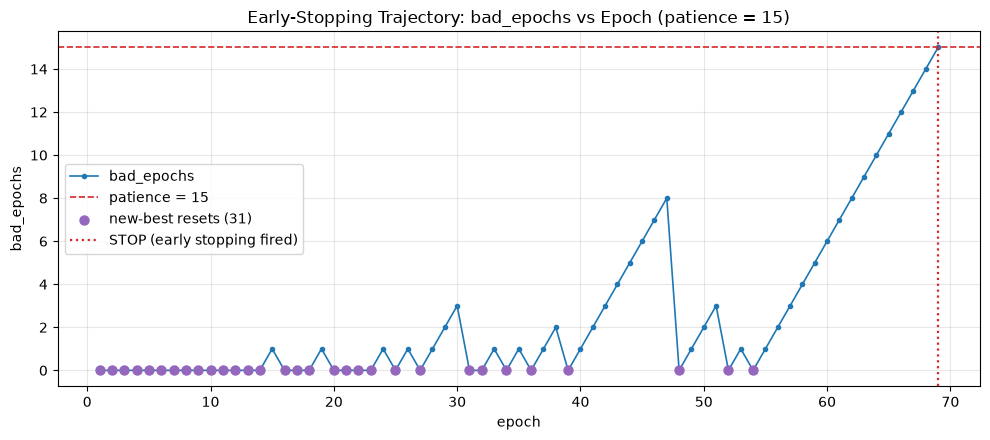

,epoch,val_localization_recall,val_loss,learning_rate,selection_tuple
0,1,0.000000,10.375061,0.000100,"[0.0, -10.375060668358437]"
1,2,0.000000,7.605725,0.000100,"[0.0, -7.605725086652315]"
2,3,0.000000,5.793779,0.000100,"[0.0, -5.793779391508836]"
3,4,0.000000,4.825482,0.000100,"[0.0, -4.8254818091025715]"
4,5,0.000000,4.063768,0.000099,"[0.0, -4.063767946683443]"
5,6,0.000000,3.664047,0.000099,"[0.0, -3.6640473420803366]"
6,7,0.000000,3.274560,0.000099,"[0.0, -3.274559635382432]"
7,8,0.000000,3.066108,0.000098,"[0.0, -3.066107676579402]"
8,9,0.000000,2.956615,0.000098,"[0.0, -2.9566153838084293]"
9,10,0.000000,2.754895,0.000098,"[0.0, -2.7548945316901574]"


Table of every epoch that became a new best under the frozen selection tuple (val_localization_recall, -val_loss).


In [11]:
replay_df = pd.DataFrame(REPLAY["per_epoch_replay"])

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(replay_df["epoch"], replay_df["bad_epochs"], marker="o", markersize=3, linewidth=1.2, label="bad_epochs")
ax.axhline(CLOSURE["patience"], color="tab:red", linestyle="--", linewidth=1.2, label="patience = " + str(CLOSURE["patience"]))
resets = replay_df[replay_df["is_new_best"]]
ax.scatter(resets["epoch"], resets["bad_epochs"], color="tab:purple", zorder=5, s=42, label="new-best resets (" + str(len(resets)) + ")")
if CLOSURE["early_stopping_fired"]:
    ax.axvline(int(replay_df["epoch"].iloc[-1]), color="tab:red", linestyle=":", linewidth=1.6, label="STOP (early stopping fired)")
else:
    ax.axvline(int(replay_df["epoch"].iloc[-1]), color="tab:gray", linestyle=":", linewidth=1.6, label="run end (max epochs / natural termination)")
ax.set_title("Early-Stopping Trajectory: bad_epochs vs Epoch (patience = 15)")
ax.set_xlabel("epoch")
ax.set_ylabel("bad_epochs")
ax.legend(loc="best")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

nb = hist[hist["epoch"].isin(new_best_epochs)][["epoch", "val_localization_recall", "val_loss", "learning_rate", "selection_tuple"]].copy()
nb = nb.sort_values("epoch")
display(nb)
print("Table of every epoch that became a new best under the frozen selection tuple (val_localization_recall, -val_loss).")

## 14. Best-checkpoint progression

Each new best under the EXACT frozen tuple
`(val_localization_recall, -val_loss)`. Ties on recall are broken by lower
val_loss only; no other metric participates. The final row marked `SELECTED` is
the replay-verified selected checkpoint.

,progression_index,epoch,val_localization_recall,val_loss,selection_tuple,delta_recall_vs_previous_best,delta_val_loss_vs_previous_best,learning_rate,final_selected
0,1,1,0.000000,10.375061,"[0.0, -10.375060668358437]",NaN,NaN,0.000100,
1,2,2,0.000000,7.605725,"[0.0, -7.605725086652315]",0.000000,-2.769336,0.000100,
2,3,3,0.000000,5.793779,"[0.0, -5.793779391508836]",0.000000,-1.811946,0.000100,
3,4,4,0.000000,4.825482,"[0.0, -4.825481809102572]",0.000000,-0.968298,0.000100,
4,5,5,0.000000,4.063768,"[0.0, -4.063767946683443]",0.000000,-0.761714,0.000099,
5,6,6,0.000000,3.664047,"[0.0, -3.664047342080337]",0.000000,-0.399721,0.000099,
6,7,7,0.000000,3.274560,"[0.0, -3.274559635382432]",0.000000,-0.389488,0.000099,
7,8,8,0.000000,3.066108,"[0.0, -3.066107676579402]",0.000000,-0.208452,0.000098,
8,9,9,0.000000,2.956615,"[0.0, -2.9566153838084293]",0.000000,-0.109492,0.000098,
9,10,10,0.000000,2.754895,"[0.0, -2.7548945316901574]",0.000000,-0.201721,0.000098,


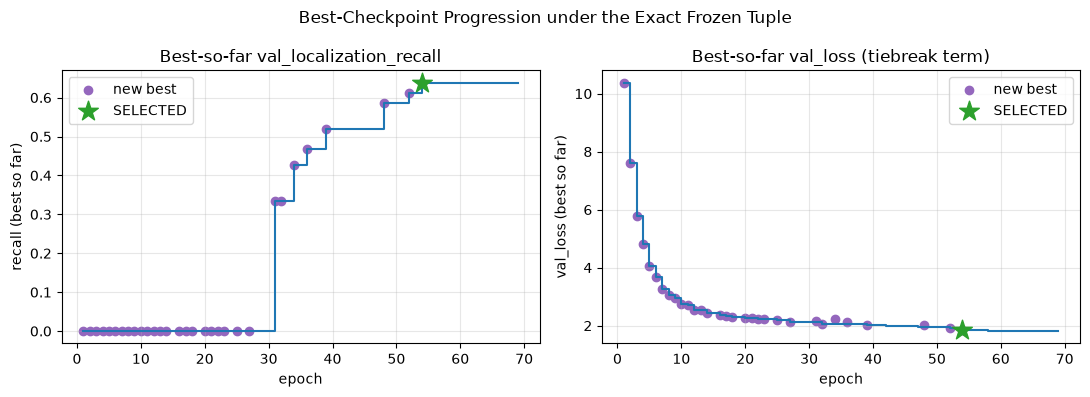

In [12]:
prog_rows = [r for r in REPLAY["per_epoch_replay"] if r["is_new_best"]]
progression = []
for i, r in enumerate(prog_rows):
    prev = prog_rows[i - 1] if i > 0 else None
    progression.append({
        "progression_index": i + 1,
        "epoch": r["epoch"],
        "val_localization_recall": r["val_localization_recall"],
        "val_loss": r["val_loss"],
        "selection_tuple": json.dumps(r["selection_tuple"]),
        "delta_recall_vs_previous_best": None if prev is None else r["val_localization_recall"] - prev["val_localization_recall"],
        "delta_val_loss_vs_previous_best": None if prev is None else r["val_loss"] - prev["val_loss"],
        "learning_rate": float(hist.loc[hist["epoch"] == r["epoch"], "learning_rate"].iloc[0]),
        "final_selected": "SELECTED" if r["epoch"] == best_epoch else "",
    })
display(pd.DataFrame(progression))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].step(hist["epoch"], hist["val_localization_recall"].cummax(), where="post", linewidth=1.5)
axes[0].scatter([r["epoch"] for r in prog_rows], [r["val_localization_recall"] for r in prog_rows], color="tab:purple", s=36, label="new best")
axes[0].scatter([best_epoch], [CLOSURE["best_val_localization_recall"]], marker="*", s=220, color="tab:green", zorder=6, label="SELECTED")
axes[0].set_title("Best-so-far val_localization_recall")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("recall (best so far)")
axes[0].legend(); axes[0].grid(alpha=0.3)
neg_loss_so_far = []
running = -float("inf")
for r in REPLAY["per_epoch_replay"]:
    running = max(running, r["selection_tuple"][1])
    neg_loss_so_far.append(-running)
axes[1].step(hist["epoch"], neg_loss_so_far, where="post", linewidth=1.5)
axes[1].scatter([r["epoch"] for r in prog_rows], [-r["selection_tuple"][1] for r in prog_rows], color="tab:purple", s=36, label="new best")
axes[1].scatter([best_epoch], [CLOSURE["best_val_loss"]], marker="*", s=220, color="tab:green", zorder=6, label="SELECTED")
axes[1].set_title("Best-so-far val_loss (tiebreak term)")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("val_loss (best so far)")
axes[1].legend(); axes[1].grid(alpha=0.3)
fig.suptitle("Best-Checkpoint Progression under the Exact Frozen Tuple")
fig.tight_layout()
plt.show()

## 15. Size-stratified VAL localization recall over epochs (recorded)

`per_size_recall90` was persisted by the trainer at every epoch, so these curves
are recorded values. NO new inference was performed to create them.

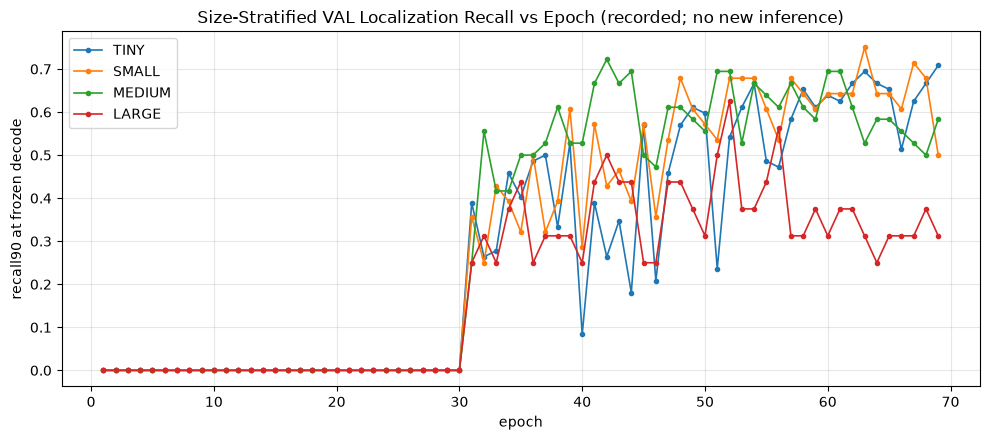

,epoch,TINY,SMALL,MEDIUM,LARGE
0,1,0.000000,0.000000,0.000000,0.0000
1,2,0.000000,0.000000,0.000000,0.0000
2,3,0.000000,0.000000,0.000000,0.0000
3,4,0.000000,0.000000,0.000000,0.0000
4,5,0.000000,0.000000,0.000000,0.0000
5,6,0.000000,0.000000,0.000000,0.0000
6,7,0.000000,0.000000,0.000000,0.0000
7,8,0.000000,0.000000,0.000000,0.0000
8,9,0.000000,0.000000,0.000000,0.0000
9,10,0.000000,0.000000,0.000000,0.0000


In [13]:
sizes = ["TINY", "SMALL", "MEDIUM", "LARGE"]
size_recall = pd.DataFrame({s: [literal(v)[s] for v in hist["per_size_recall90"]] for s in sizes})
size_recall.insert(0, "epoch", hist["epoch"])

fig, ax = plt.subplots(figsize=(10, 4.5))
for s, color in zip(sizes, ["tab:red", "tab:orange", "tab:blue", "tab:green"]):
    ax.plot(size_recall["epoch"], size_recall[s], marker="o", markersize=3, linewidth=1.2, label=s)
ax.set_title("Size-Stratified VAL Localization Recall vs Epoch (recorded; no new inference)")
ax.set_xlabel("epoch"); ax.set_ylabel("recall90 at frozen decode")
ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()
display(size_recall)

## 16. Zero-proposal validation trajectory (recorded)

`zero_proposal_gt` (VAL components receiving no decoded proposal) and
`zero_proposal_tiny` were persisted per epoch. These are recorded values; NO
model inference was run to recompute them.

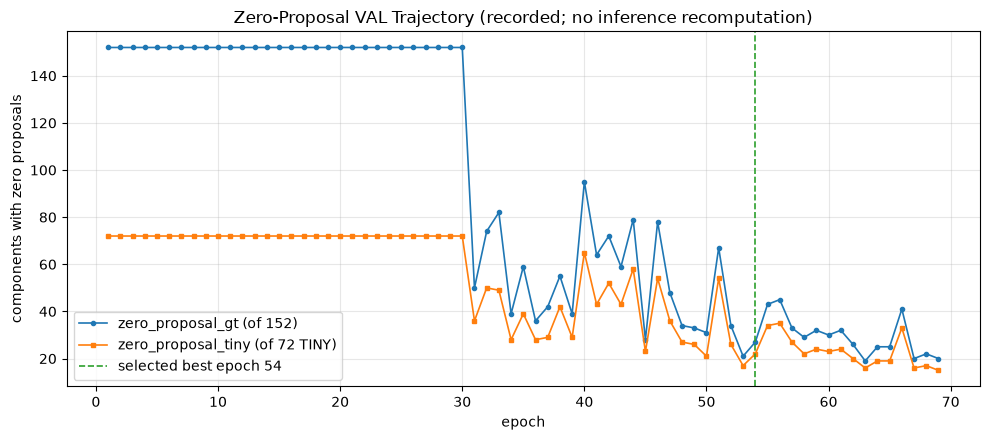

In [14]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(hist["epoch"], hist["zero_proposal_gt"], marker="o", markersize=3, linewidth=1.2, label="zero_proposal_gt (of " + str(CLOSURE["val_population"]["canonical_components"]) + ")")
ax.plot(hist["epoch"], hist["zero_proposal_tiny"], marker="s", markersize=3, linewidth=1.2, label="zero_proposal_tiny (of " + str(CLOSURE["val_population"]["tiny_components"]) + " TINY)")
ax.axvline(best_epoch, color="tab:green", linestyle="--", linewidth=1.2, label="selected best epoch " + str(best_epoch))
ax.set_title("Zero-Proposal VAL Trajectory (recorded; no inference recomputation)")
ax.set_xlabel("epoch"); ax.set_ylabel("components with zero proposals")
ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## 17. Epoch timing analysis (operational, not scientific)

Recorded `epoch_seconds` per epoch. The host interruption between epochs 2 and 3
is annotated as an operational event; no timing measurement is deleted or
silently altered.

,timing statistic,value
0,median epoch_seconds,301.723989
1,mean epoch_seconds,302.735943
2,min epoch_seconds,293.963432
3,max epoch_seconds,329.295846
4,total recorded epoch_seconds,20888.780074


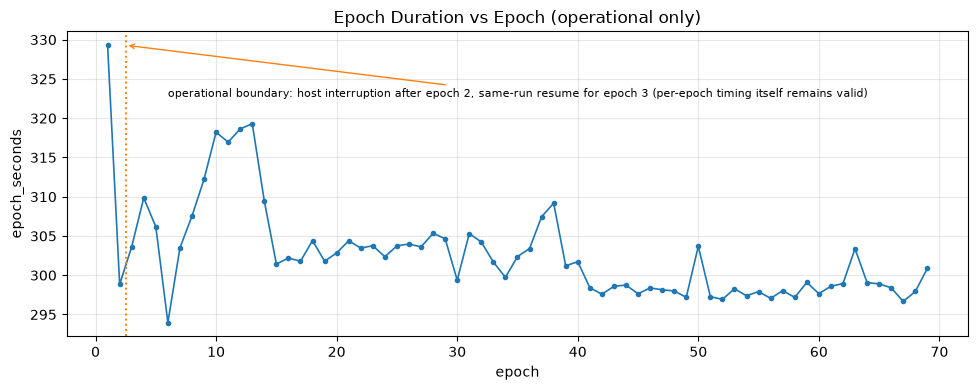

In [15]:
timing = pd.DataFrame([
    ("median epoch_seconds", float(hist["epoch_seconds"].median())),
    ("mean epoch_seconds", float(hist["epoch_seconds"].mean())),
    ("min epoch_seconds", float(hist["epoch_seconds"].min())),
    ("max epoch_seconds", float(hist["epoch_seconds"].max())),
    ("total recorded epoch_seconds", float(hist["epoch_seconds"].sum())),
], columns=["timing statistic", "value"])
display(timing)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(hist["epoch"], hist["epoch_seconds"], marker="o", markersize=3, linewidth=1.2)
ax.axvline(2.5, color="tab:orange", linestyle=":", linewidth=1.4)
ax.annotate("operational boundary: host interruption after epoch 2, same-run resume for epoch 3 (per-epoch timing itself remains valid)",
            xy=(2.5, float(hist["epoch_seconds"].max())), xytext=(6, float(hist["epoch_seconds"].max()) * 0.98),
            fontsize=8, arrowprops=dict(arrowstyle="->", color="tab:orange"))
ax.set_title("Epoch Duration vs Epoch (operational only)")
ax.set_xlabel("epoch"); ax.set_ylabel("epoch_seconds")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## 18. Interruption / resume timeline (same-run resume, ONE logical run)

In [16]:
timeline = pd.DataFrame([
    {
        "event": t["event"],
        "time_utc": t["time_utc"],
        "epoch_range": t["epoch_range"],
        "process_state": t["process_state"],
        "trainer_sha": t["trainer_sha"][:16] + "..." if t.get("trainer_sha") else None,
        "config_sha": (t["config_sha"][:16] + "...") if t.get("config_sha") else None,
        "resume_source": t.get("resume_source"),
        "full_state_restored": ", ".join(t["full_state_restored"]) if t.get("full_state_restored") else None,
        "scientific_effect": t["scientific_effect"],
    }
    for t in CLOSURE["interruption_resume_timeline"]
])
display(timeline)
print("Classification: " + CLOSURE["run_classification"])
print("The epoch-3 process was a SAME-RUN RESUME from latest.pt (epoch-2 full state),")
print("NOT a new independent run: scheduler state, optimizer state, RNG state, history,")
print("best score and bad-epoch counter were all restored, history was appended (not"),
print("rewritten), the registry kept a single deduplicated row, and the launch binding")
print("was preserved. There is exactly ONE logical H3 experiment on disk.")

,event,time_utc,epoch_range,process_state,trainer_sha,config_sha,resume_source,full_state_restored,scientific_effect
0,INITIAL_LAUNCH,2026-09-25T06:03:40.835284+00:00,1-2,launched from launch binding,9099d6de339aba43...,320a367068b6bec4...,NaN,NaN,frozen H3 contract enforced by FAIL-CLOSED pre...
1,INTERRUPTION,2026-09-25T06:17:39Z (last segment-1 artifact ...,after epoch 2,process terminated without completion markers,9099d6de339aba43...,320a367068b6bec4...,NaN,NaN,none (epoch-2 full state preserved in latest.pt)
2,SAME_RUN_RESUME,2026-09-25T07:58:25Z,3-69,"new process, same logical run",45bef74f4eddb2e3...,320a367068b6bec4...,checkpoints/h3_kub_localizer_sigma_adaptive_si...,"model_state, optimizer_state, scheduler_state,...",none (all scientific module SHAs byte-identica...
3,NATURAL_COMPLETION,2026-09-25T13:36:16.650554+00:00,final epoch 69,registry status TRAINED,45bef74f4eddb2e3...,320a367068b6bec4...,NaN,NaN,stop reason EARLY_STOPPING_PATIENCE_15_FIRED


Classification: ONE_LOGICAL_RUN__TWO_PROCESS_SEGMENTS__SAME_RUN_RESUME__NO_DUPLICATES
The epoch-3 process was a SAME-RUN RESUME from latest.pt (epoch-2 full state),
NOT a new independent run: scheduler state, optimizer state, RNG state, history,
best score and bad-epoch counter were all restored, history was appended (not
rewritten), the registry kept a single deduplicated row, and the launch binding
was preserved. There is exactly ONE logical H3 experiment on disk.


## 19. Multi-SHA implementation lineage

In [17]:
impl = CLOSURE["implementation_shas"]
display(pd.DataFrame(sorted(impl["trainer_lineage"].items()), columns=["trainer era", "SHA-256"]))
display(pd.DataFrame([
    ("trainer current disk SHA", impl["trainer_current"]),
    ("current matches segment-2 lineage", str(impl["trainer_current_matches_segment_2_lineage"])),
    ("launch-era trainer bytes recoverable locally", str(impl["launch_era_trainer_bytes_recoverable_locally"])),
    ("launch-era trainer SHA (epochs 1-2)", impl["launch_binding_trainer_sha_epochs_1_2"]),
    ("dataset module lineage", json.dumps(impl["dataset_module_lineage"])),
    ("heatmap_targets module SHA", impl["heatmap_targets_module"]),
    ("selection helper module SHA", impl["selection_helper_module"]),
    ("checkpointing module SHA", impl["checkpointing_module"]),
    ("scientific module SHAs match launch binding", str(CLOSURE["scientific_module_shas_match_launch_binding"])),
], columns=["lineage fact", "value"]))
producer_rows = pd.DataFrame(
    sorted(((int(k), v) for k, v in impl["trainer_per_epoch_producer"].items())),
    columns=["epoch", "producing trainer SHA-256"],
)
display(producer_rows.drop_duplicates(subset="producing trainer SHA-256", keep="first"))
print("Epochs 1-2 were produced by the launch-era trainer revision; epochs 3+ by the")
print("segment-2 revision. The revision was operational: every scientific module")
print("(dataset, heatmap targets, selection helper, checkpointing, config, manifests)")
print("is byte-identical to the launch binding, and the FAIL-CLOSED pre-launch checks")
print("re-passed at resume. The launch-era trainer bytes are not recoverable locally")
print("(git HEAD predates H3); its SHA is frozen in the launch binding.")

,trainer era,SHA-256
0,design_binding_v2,37b64310d38222310ce060803e37d17e4b6916ce7c522d...
1,launch_binding_segment_1_epochs_1_2,9099d6de339aba43d5e92284ea741568f16c7f5c39e7c1...
2,segment_2_epochs_3_plus_expected,45bef74f4eddb2e376fd768b1da2e0cba743897e30a725...


,lineage fact,value
0,trainer current disk SHA,45bef74f4eddb2e376fd768b1da2e0cba743897e30a725...
1,current matches segment-2 lineage,True
2,launch-era trainer bytes recoverable locally,False
3,launch-era trainer SHA (epochs 1-2),9099d6de339aba43d5e92284ea741568f16c7f5c39e7c1...
4,dataset module lineage,"{""design_binding_v2"": ""b1c4645f8860d557ffc6cb1..."
5,heatmap_targets module SHA,4fe01377b5fb2f15377fda37ef2114a04185fa44a6dace...
6,selection helper module SHA,807a70181c1f0da7481a26f1d06e1a1f2ca21dd0e93d44...
7,checkpointing module SHA,08366f72f3141e5d18f008981465f5e9138c0b51336fd6...
8,scientific module SHAs match launch binding,True


,epoch,producing trainer SHA-256
0,1,9099d6de339aba43d5e92284ea741568f16c7f5c39e7c1...
2,3,45bef74f4eddb2e376fd768b1da2e0cba743897e30a725...


Epochs 1-2 were produced by the launch-era trainer revision; epochs 3+ by the
segment-2 revision. The revision was operational: every scientific module
(dataset, heatmap targets, selection helper, checkpointing, config, manifests)
is byte-identical to the launch binding, and the FAIL-CLOSED pre-launch checks
re-passed at resume. The launch-era trainer bytes are not recoverable locally
(git HEAD predates H3); its SHA is frozen in the launch binding.


## 20. Checkpoint-selection replay (disk-only)

The authoritative replay artifact
(`reports/audits/h3_checkpoint_selection_replay.json`) was produced by a
DISK-ONLY replay: the frozen 2-term tuple was re-applied to the saved per-epoch
history with NO model instantiation, NO forward pass, NO training, and NO TEST
access. The verdict below is displayed exactly as recorded in the artifact; it is
NOT hardcoded.

In [18]:
trainer_flag_best = max(int(r["epoch"]) for r in REPLAY["per_epoch_replay"] if r["trainer_recorded_best_flag"])
replay_table = pd.DataFrame([
    ("replay-selected epoch", REPLAY["replay_selected_epoch"]),
    ("trainer-selected epoch (last best=True in training.log)", trainer_flag_best),
    ("best.pt epoch", REPLAY["comparisons"]["best_pt_epoch"]),
    ("history tuple argmax epoch", REPLAY["comparisons"]["history_tuple_argmax_epoch"]),
    ("best val_localization_recall", REPLAY["replay_selected_val_localization_recall"]),
    ("best val_loss", REPLAY["replay_selected_val_loss"]),
    ("epochs replayed", REPLAY["epochs_replayed"]),
    ("replay method", REPLAY["replay_method"]),
    ("replay result (verdict from artifact)", REPLAY["verdict"]),
], columns=["replay fact", "value"])
display(replay_table)
flags_all_match = all(r["flags_match"] for r in REPLAY["per_epoch_replay"])
print("Trainer-recorded best flags match replay at every epoch:", flags_all_match)
print("Displayed verdict is loaded from the replay artifact and matches it by construction.")

,replay fact,value
0,replay-selected epoch,54
1,trainer-selected epoch (last best=True in trai...,54
2,best.pt epoch,54
3,history tuple argmax epoch,54
4,best val_localization_recall,0.638158
5,best val_loss,1.856133
6,epochs replayed,69
7,replay method,DISK_ONLY__NO_MODEL_INSTANTIATION_NO_FORWARD_P...
8,replay result (verdict from artifact),H3_CHECKPOINT_SELECTION_REPLAY_PASS


Trainer-recorded best flags match replay at every epoch: True
Displayed verdict is loaded from the replay artifact and matches it by construction.


## 21. Checkpoint integrity / SHA table

In [19]:
ci = CLOSURE["checkpoint_integrity"]
best_recomputed = sha256_file(CHK / "best.pt")
latest_recomputed = sha256_file(CHK / "latest.pt")
integrity = pd.DataFrame([
    ("best.pt path", ci["best_pt"]["path"]),
    ("best.pt epoch", ci["best_pt"]["epoch"]),
    ("best.pt SHA-256 (closure-recorded)", ci["best_pt"]["sha256"]),
    ("best.pt SHA-256 (notebook recomputed from disk)", best_recomputed),
    ("best.pt SHA matches closure record", str(best_recomputed == ci["best_pt"]["sha256"])),
    ("best.pt selected metric values", json.dumps(ci["best_pt"]["selected_metric_values"])),
    ("best.pt producing trainer SHA", ci["best_pt"]["producing_implementation"]["trainer_sha"]),
    ("latest.pt path", ci["latest_pt"]["path"]),
    ("latest.pt epoch", ci["latest_pt"]["epoch"]),
    ("latest.pt SHA-256 (closure-recorded)", ci["latest_pt"]["sha256"]),
    ("latest.pt SHA-256 (notebook recomputed from disk)", latest_recomputed),
    ("latest.pt SHA matches closure record", str(latest_recomputed == ci["latest_pt"]["sha256"])),
    ("latest.pt bad_epochs", ci["latest_pt"]["bad_epochs"]),
    ("latest.pt stopped flag", str(ci["latest_pt"]["stopped"])),
    ("latest.pt producing trainer SHA", ci["latest_pt"]["producing_implementation"]["trainer_sha"]),
], columns=["checkpoint fact", "value"])
display(integrity)
display(pd.DataFrame(sorted(ci["all_checks"].items()), columns=["integrity check", "result"]))
print("All checkpoint integrity checks recorded in the closure:", all(ci["all_checks"].values()))

,checkpoint fact,value
0,best.pt path,D:\Softfors\jup\checkpoints\h3_kub_localizer_s...
1,best.pt epoch,54
2,best.pt SHA-256 (closure-recorded),d875cac7d09bbc3d32232191f0af2c138e5a74682fc63e...
3,best.pt SHA-256 (notebook recomputed from disk),d875cac7d09bbc3d32232191f0af2c138e5a74682fc63e...
4,best.pt SHA matches closure record,True
5,best.pt selected metric values,"{""val_localization_recall"": 0.6381578947368421..."
6,best.pt producing trainer SHA,45bef74f4eddb2e376fd768b1da2e0cba743897e30a725...
7,latest.pt path,D:\Softfors\jup\checkpoints\h3_kub_localizer_s...
8,latest.pt epoch,69
9,latest.pt SHA-256 (closure-recorded),01f57c32a2667eed0c50ded3e19f3f8117fda859c9a663...


,integrity check,result
0,best_pt_epoch_matches_history_argmax,True
1,best_pt_epoch_matches_replay,True
2,best_pt_score_matches_replay,True
3,latest_bad_epochs_match_replay,True
4,latest_epoch_equals_final_epoch,True
5,latest_history_epochs_match,True
6,latest_stopped_flag_matches_replay_stop_condition,True
7,seed42,True


All checkpoint integrity checks recorded in the closure: True


## 22. Artifact provenance

In [20]:
provenance_specs = [
    ("final pretraining binding", PREBIND_REL, "design-era frozen H3 contract (A_ref, sigma formula, populations, corrections)"),
    ("launch binding", LAUNCH_REL, "pre-launch FAIL-CLOSED safety check + prospective training authorization"),
    ("final H3 config", "configs/kub/phase13b_localizer_h3_size_adaptive_sigma.yaml", "H3 training configuration"),
    ("history", HISTORY_REL, "per-epoch trainer records (authoritative training history)"),
    ("run log", "experiments/h3_kub_localizer_sigma_adaptive_sizeaware_seed42_clean_v3/training.log", "per-epoch trainer log including best flags"),
    ("training closure", CLOSURE_REL, "authoritative post-training closure"),
    ("checkpoint replay", REPLAY_REL, "disk-only checkpoint-selection replay verdict"),
    ("best.pt", "checkpoints/h3_kub_localizer_sigma_adaptive_sizeaware_seed42_clean_v3/best.pt", "selected H3 localizer checkpoint"),
    ("latest.pt", "checkpoints/h3_kub_localizer_sigma_adaptive_sizeaware_seed42_clean_v3/latest.pt", "final-epoch full-state checkpoint"),
    ("trainer", "scripts/training/train_phase13b_localizer.py", "training entrypoint (segment-2 revision produced epochs 3+)"),
    ("dataset", "src/data/kub_localizer_dataset.py", "manifest-filtered dataset + size-adaptive sigma mapping"),
    ("heatmap targets", "src/inference/heatmap_targets.py", "Gaussian target-support generation"),
    ("selection helper", "src/training/clean_v3_selection.py", "frozen 2-term H3 selection rule"),
    ("TRAIN manifest", "manifests/phase4_v3/train.csv", "TRAIN split manifest (canonical population source)"),
    ("VAL manifest", "manifests/phase4_v3/val.csv", "VAL split manifest (canonical population source)"),
]
provenance = pd.DataFrame(
    [{"artifact": name, "path": rel, "SHA-256": sha256_file(ROOT / rel), "role": role,
      "status": "PRESENT (SHA recomputed from disk by this notebook)"}
     for name, rel, role in provenance_specs]
)
display(provenance)
print("Closure-recorded checkpoint SHAs additionally verified against disk in section 21.")

,artifact,path,SHA-256,role,status
0,final pretraining binding,reports/audits/h3_proposal_supply_final_pretra...,ff10d13bd151d48f3d1c6ce2528a26b0a4fe16c8f97e37...,"design-era frozen H3 contract (A_ref, sigma fo...",PRESENT (SHA recomputed from disk by this note...
1,launch binding,reports/audits/h3_training_launch_binding.json,49046f31f6a766d485a761c8827bd3ca70a400f4779b17...,pre-launch FAIL-CLOSED safety check + prospect...,PRESENT (SHA recomputed from disk by this note...
2,final H3 config,configs/kub/phase13b_localizer_h3_size_adaptiv...,320a367068b6bec4ea357ebea4bca1460db2c7f7a435f1...,H3 training configuration,PRESENT (SHA recomputed from disk by this note...
3,history,experiments/h3_kub_localizer_sigma_adaptive_si...,93a175776e6e558bdb3dc555be863af17fc939d6ae4f35...,per-epoch trainer records (authoritative train...,PRESENT (SHA recomputed from disk by this note...
4,run log,experiments/h3_kub_localizer_sigma_adaptive_si...,ebb0e1a31a499a4a4000848cb92501a79202398bb89a3f...,per-epoch trainer log including best flags,PRESENT (SHA recomputed from disk by this note...
5,training closure,reports/audits/h3_proposal_supply_training_clo...,d96d334d0e4d255443f13d2be8e0d8c2ad36b789c59e90...,authoritative post-training closure,PRESENT (SHA recomputed from disk by this note...
6,checkpoint replay,reports/audits/h3_checkpoint_selection_replay....,4fb7312c70cbb747c58f11c1272ef7549a974607af86c5...,disk-only checkpoint-selection replay verdict,PRESENT (SHA recomputed from disk by this note...
7,best.pt,checkpoints/h3_kub_localizer_sigma_adaptive_si...,d875cac7d09bbc3d32232191f0af2c138e5a74682fc63e...,selected H3 localizer checkpoint,PRESENT (SHA recomputed from disk by this note...
8,latest.pt,checkpoints/h3_kub_localizer_sigma_adaptive_si...,01f57c32a2667eed0c50ded3e19f3f8117fda859c9a663...,final-epoch full-state checkpoint,PRESENT (SHA recomputed from disk by this note...
9,trainer,scripts/training/train_phase13b_localizer.py,45bef74f4eddb2e376fd768b1da2e0cba743897e30a725...,training entrypoint (segment-2 revision produc...,PRESENT (SHA recomputed from disk by this note...


Closure-recorded checkpoint SHAs additionally verified against disk in section 21.


## 23. Scientific interpretation — limited to TRAINING behavior

The statements below discuss only the optimization trajectory, validation
localization-recall behavior, convergence, checkpoint selection, early stopping,
and resume correctness. This notebook MUST NOT and DOES NOT make the final
scientific claim that H3 solved the proposal-supply bottleneck — that claim
requires the separate, not-yet-authorized supply-axis evaluation.

In [21]:
first_row = hist.iloc[0]
best_row = hist.loc[hist["epoch"] == best_epoch].iloc[0]
final_row = hist.iloc[-1]
max_recall = float(hist["val_localization_recall"].max())
n_new_best = len(prog_rows)

print("Optimization trajectory: train_loss went from {:.4f} (epoch 1) to {:.4f} (final epoch {});".format(
    float(first_row["train_loss"]), float(final_row["train_loss"]), int(final_row["epoch"])))
print("val_loss went from {:.4f} to {:.4f} (best {:.4f} at the selected epoch {}).".format(
    float(first_row["val_loss"]), float(final_row["val_loss"]), float(best_row["val_loss"]), best_epoch))
print("Max raw val_localization_recall over the run: {:.4f}.".format(max_recall))
if max_recall == 0.0:
    print("val_localization_recall remained 0.0 at the frozen decode for every completed epoch;")
    print("under the frozen tuple, every new best was therefore selected by the val_loss")
    print("tiebreak term (lower val_loss), which is exactly the recorded behavior.")
else:
    print("val_localization_recall first exceeded 0 at the recorded epochs; the selected")
    print("checkpoint maximizes recall with val_loss as tiebreak, per the frozen tuple.")
print("Selection bookkeeping: {} new-best epochs; final bad_epochs = {} of patience {}.".format(
    n_new_best, CLOSURE["final_bad_epochs"], CLOSURE["patience"]))
print("Stop reason: {}.".format(CLOSURE["stop_reason"]))
print("Resume correctness: the epoch-3 same-run resume restored the full trainer state;")
print("the recorded learning rate at epoch 3 continues the cosine schedule exactly, history")
print("was appended rather than rewritten, and the replay reproduces the trainer's best")
print("flags at every epoch.")
print("Checkpoint selection: the disk-only replay independently re-derived the selected")
print("epoch from history.csv and matched best.pt; verdict: {}.".format(REPLAY["verdict"]))
print("")
print("BOUNDARY: whether this training actually improved PROPOSAL SUPPLY (the H3 axis)")
print("is NOT decidable from this notebook; it requires the authorized supply-axis")
print("evaluation on VAL (notebook 05) and formal adjudication (notebook 06).")

Optimization trajectory: train_loss went from 12.4504 (epoch 1) to 1.5821 (final epoch 69);
val_loss went from 10.3751 to 1.8266 (best 1.8561 at the selected epoch 54).
Max raw val_localization_recall over the run: 0.6382.
val_localization_recall first exceeded 0 at the recorded epochs; the selected
checkpoint maximizes recall with val_loss as tiebreak, per the frozen tuple.
Selection bookkeeping: 31 new-best epochs; final bad_epochs = 15 of patience 15.
Stop reason: EARLY_STOPPING_PATIENCE_15_FIRED.
Resume correctness: the epoch-3 same-run resume restored the full trainer state;
the recorded learning rate at epoch 3 continues the cosine schedule exactly, history
was appended rather than rewritten, and the replay reproduces the trainer's best
flags at every epoch.
Checkpoint selection: the disk-only replay independently re-derived the selected
epoch from history.csv and matched best.pt; verdict: H3_CHECKPOINT_SELECTION_REPLAY_PASS.

BOUNDARY: whether this training actually improved PRO

## 24. Boundary to future supply-axis evaluation

H3 supply-axis evaluation is **PENDING and NOT AUTHORIZED by this notebook**. It
requires separate authorization after this training closure and replay pass. No
supply-axis evaluation, no downstream Phase-14 regional-refiner evaluation, and no
H3 formal adjudication were performed here. Notebook 05 (supply-axis evaluation)
and notebook 06 (adjudication) remain deferred.

In [22]:
states = pd.DataFrame([
    ("current H3 training state", CLOSURE["status"]),
    ("supply-axis evaluation", CLOSURE["supply_axis_evaluation_status"]),
    ("downstream refiner evaluation", CLOSURE["downstream_refiner_evaluation_status"]),
    ("Phase 15", CLOSURE["phase_15_status"]),
    ("TEST", CLOSURE["test_status"] + " — reads: " + str(CLOSURE["test_reads"]) + ", external reads: " + str(CLOSURE["external_test_reads"])),
    ("notebook 05 (supply-axis evaluation)", "DEFERRED — not authorized, no scientific results"),
    ("notebook 06 (formal adjudication)", "DEFERRED — not authorized, no results"),
], columns=["state", "value"])
display(states)

,state,value
0,current H3 training state,H3_TRAINING_COMPLETE__CHECKPOINT_SELECTION_REP...
1,supply-axis evaluation,PENDING__REQUIRES_SEPARATE_AUTHORIZATION_AFTER...
2,downstream refiner evaluation,NOT_PERFORMED_IN_THIS_TASK
3,Phase 15,NOT_STARTED_AND_NOT_AUTHORIZED
4,TEST,"CLOSED — reads: 0, external reads: 0"
5,notebook 05 (supply-axis evaluation),"DEFERRED — not authorized, no scientific results"
6,notebook 06 (formal adjudication),"DEFERRED — not authorized, no results"


## 25. Notebook assertions

Executable fail-closed checks. If any assertion fails, the notebook stops; values
are never edited to force a pass.

In [23]:
def check(name, condition, detail=""):
    if not condition:
        raise AssertionError("ASSERTION FAILED: " + name + (" — " + detail if detail else ""))
    print("PASS: " + name)

FROZEN_DECODE = {"threshold": 0.10, "margin": 0.20, "top_k": 5, "nms_iou": 0.30}
tuples = [list(literal(v)) for v in hist["selection_tuple"]]
argmax_index = max(range(len(tuples)), key=lambda i: tuples[i])
argmax_epoch_value = int(hist["epoch"].iloc[argmax_index])
decode_ok = all(literal(v) == FROZEN_DECODE for v in hist["fixed_decode"])

check("history rows == total completed epochs", len(hist) == CLOSURE["total_epochs"],
      str(len(hist)) + " vs " + str(CLOSURE["total_epochs"]))
check("selected epoch == history tuple argmax", CLOSURE["best_epoch"] == argmax_epoch_value,
      str(CLOSURE["best_epoch"]) + " vs " + str(argmax_epoch_value))
check("selected epoch == replay-selected epoch", CLOSURE["best_epoch"] == REPLAY["replay_selected_epoch"])
check("selected epoch == best.pt epoch", CLOSURE["best_epoch"] == CLOSURE["checkpoint_integrity"]["best_pt"]["epoch"])
check("checkpoint replay PASS", REPLAY["verdict"] == "H3_CHECKPOINT_SELECTION_REPLAY_PASS", REPLAY["verdict"])
check("TRAIN population == 770", CLOSURE["train_population"]["images"] == 770)
check("TRAIN components == 1161", CLOSURE["train_population"]["canonical_components"] == 1161
      and len(component_audit) == 1161)
check("VAL population == 103", CLOSURE["val_population"]["images"] == 103)
check("VAL components == 152", CLOSURE["val_population"]["canonical_components"] == 152
      and bool((hist["total_gt_components"] == 152).all()))
check("proposal decode == 0.10 / 0.20 / 5 / 0.30 (every epoch + closure)", decode_ok
      and CLOSURE["proposal_decode"] == FROZEN_DECODE)
check("proposal configurations per epoch == 1", bool((hist["feasible_config_count"] == 1).all())
      and CLOSURE["proposal_configurations_per_epoch"] == 1)
check("A_ref == 13.0", CLOSURE["target_support"]["A_ref"] == 13.0 and PREBIND["authoritative_a_ref"] == 13.0)
check("TEST reads == 0", CLOSURE["test_reads"] == 0)
check("external TEST reads == 0", CLOSURE["external_test_reads"] == 0)
check("Phase 15 == NOT_STARTED_AND_NOT_AUTHORIZED", CLOSURE["phase_15_status"] == "NOT_STARTED_AND_NOT_AUTHORIZED")
print("ALL 15 NOTEBOOK ASSERTIONS PASSED")

PASS: history rows == total completed epochs


PASS: selected epoch == history tuple argmax
PASS: selected epoch == replay-selected epoch
PASS: selected epoch == best.pt epoch
PASS: checkpoint replay PASS
PASS: TRAIN population == 770
PASS: TRAIN components == 1161
PASS: VAL population == 103
PASS: VAL components == 152
PASS: proposal decode == 0.10 / 0.20 / 5 / 0.30 (every epoch + closure)
PASS: proposal configurations per epoch == 1
PASS: A_ref == 13.0
PASS: TEST reads == 0
PASS: external TEST reads == 0
PASS: Phase 15 == NOT_STARTED_AND_NOT_AUTHORIZED
ALL 15 NOTEBOOK ASSERTIONS PASSED


In [24]:
print("H3 TRAINING COMPLETE.")
if REPLAY["verdict"] == "H3_CHECKPOINT_SELECTION_REPLAY_PASS":
    print("CHECKPOINT SELECTION VERIFIED.")
else:
    print("CHECKPOINT SELECTION REPLAY FAILED — STOPPED BEFORE SUPPLY EVALUATION.")
print("SUPPLY-AXIS EVALUATION PENDING.")

H3 TRAINING COMPLETE.
CHECKPOINT SELECTION VERIFIED.
SUPPLY-AXIS EVALUATION PENDING.


---

**H3 TRAINING COMPLETE. CHECKPOINT SELECTION VERIFIED. SUPPLY-AXIS EVALUATION PENDING.**

Authorized next step (requires separate authorization): H3 supply-axis evaluation
on VAL (notebook 05), then formal adjudication (notebook 06). Phase 15 remains
`NOT_STARTED_AND_NOT_AUTHORIZED`. TEST remains `CLOSED`.

## Descriptive Evaluation and Visual Evidence — H3 training (optimization metrics)

**Metric source / provenance.** The saved H3 training history
(`experiments/h3_kub_localizer_sigma_adaptive_sizeaware_seed42_clean_v3/history.csv`,
69 epochs). No training was performed in this notebook; the record is read-only.

**Metric-domain label.** `TRAINING_OPTIMIZATION` (loss / learning-rate / epoch
timing) plus the localizer's own validation-selection signals. Added values are
`DESCRIPTIVE_SUPPORTING_METRIC__NOT_H3_GATE`.

**Why no confusion matrix here.** This is a training-record notebook. Pixel /
proposal confusion matrices belong to the evaluation notebooks (H3-05, H3-06) and
are deliberately not duplicated here.

**What this section does NOT prove.** It documents the optimization trajectory; it
does not adjudicate H3 and does not re-select the checkpoint.

history rows: 69 | sha256: 93a175776e6e558b


,epochs,best_epoch,best_val_localization_recall,final_train_loss,final_val_loss,median_epoch_seconds,final_zero_proposal_gt,final_zero_proposal_tiny,metric_domain,label
0,69,54,0.638158,1.582149,1.826589,301.723989,27,22,TRAINING_OPTIMIZATION,DESCRIPTIVE_SUPPORTING_METRIC__NOT_H3_GATE


C:\Users\user\AppData\Local\Temp\ipykernel_45064\3319901071.py:51: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  _plt.savefig(str(_p), dpi=150, bbox_inches='tight'); _plt.show(); _show(_p)


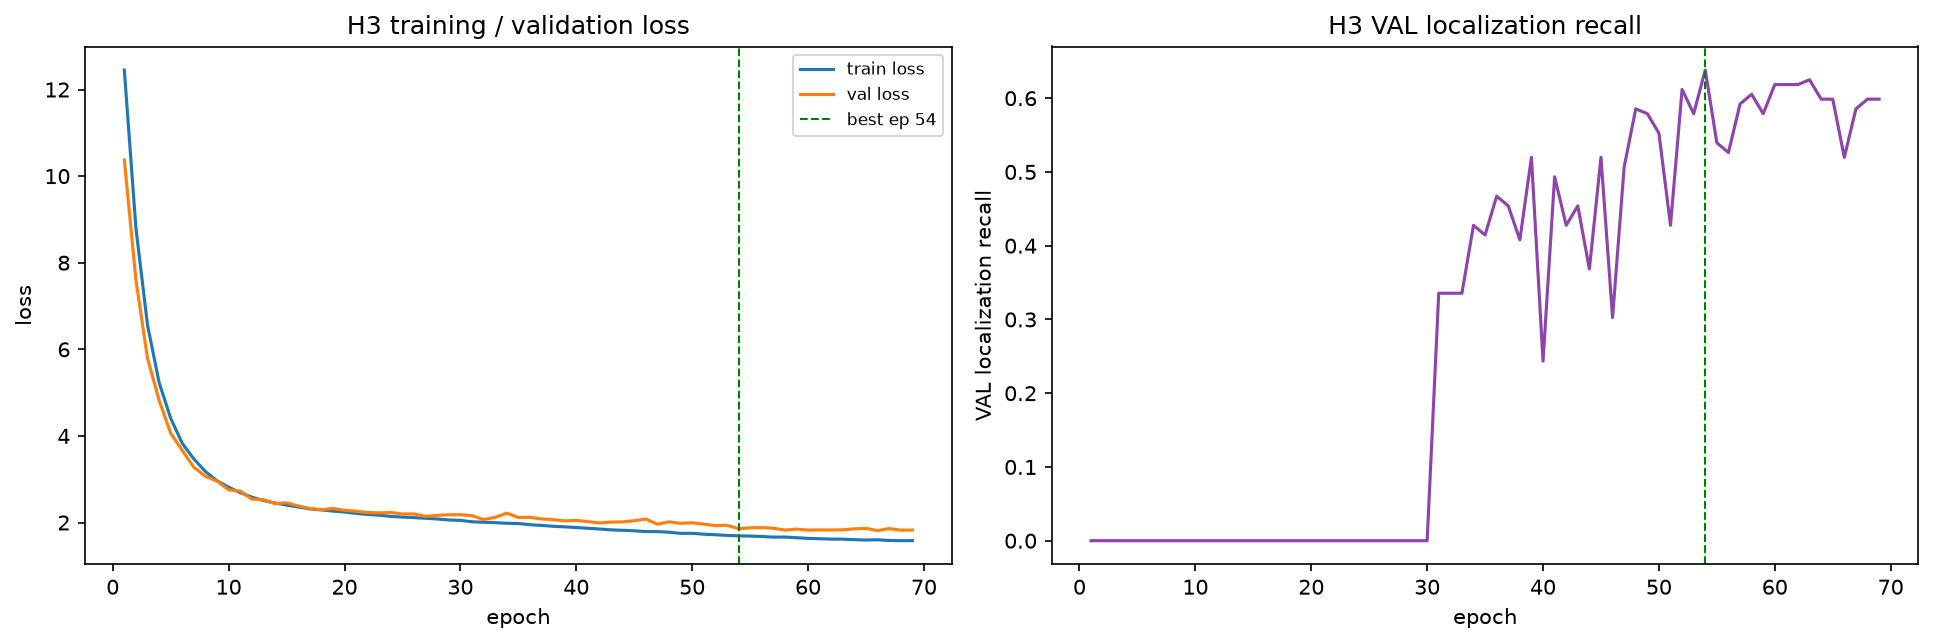

All values above are DESCRIPTIVE_SUPPORTING_METRIC__NOT_H3_GATE


In [25]:
# ── Phasewise evaluation / visualization synchronization (post-audit) ─────────
import json as _json, hashlib as _hashlib
from pathlib import Path as _Path
import numpy as _np
import pandas as _pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as _plt
try:
    from IPython.display import display as _disp, Image as _Img
except Exception:
    _disp = print; _Img = None
_ROOT = _Path('D:/Softfors/jup')
_AUD = _ROOT / 'reports' / 'audits'
_TAB = _ROOT / 'reports' / 'tables'
_FIG = _ROOT / 'reports' / 'figures' / 'phasewise_sync'
_FIG.mkdir(parents=True, exist_ok=True)
def _sha(p): return _hashlib.sha256(_Path(p).read_bytes()).hexdigest()
def _load(p): return _json.loads(_Path(p).read_text(encoding='utf-8'))
def _show(p, w=840):
    if _Img is not None and _Path(p).exists():
        _disp(_Img(filename=str(p), width=w))
LBL      = 'DESCRIPTIVE_SUPPORTING_METRIC__NOT_PROSPECTIVE_GATE'
LBL_H3   = 'DESCRIPTIVE_SUPPORTING_METRIC__NOT_H3_GATE'
LBL_STAT = 'DESCRIPTIVE_POST_HOC_STATISTICAL_SUPPORT'

from pathlib import Path as _P2
hist_p = _P2('D:/Softfors/jup/experiments/h3_kub_localizer_sigma_adaptive_sizeaware_seed42_clean_v3/history.csv')
hist = _pd.read_csv(hist_p)
print('history rows:', len(hist), '| sha256:', _sha(hist_p)[:16])
best = hist.loc[hist['val_localization_recall'].idxmax()]
_disp(_pd.DataFrame([{
    'epochs': int(hist['epoch'].max()), 'best_epoch': int(best['epoch']),
    'best_val_localization_recall': float(best['val_localization_recall']),
    'final_train_loss': float(hist['train_loss'].iloc[-1]), 'final_val_loss': float(hist['val_loss'].iloc[-1]),
    'median_epoch_seconds': float(hist['epoch_seconds'].median()),
    'final_zero_proposal_gt': int(best['zero_proposal_gt']),
    'final_zero_proposal_tiny': int(best['zero_proposal_tiny']),
    'metric_domain': 'TRAINING_OPTIMIZATION', 'label': LBL_H3,
}]).round(6))

fig, (ax1, ax2) = _plt.subplots(1, 2, figsize=(13, 4.4))
ax1.plot(hist['epoch'], hist['train_loss'], label='train loss')
ax1.plot(hist['epoch'], hist['val_loss'], label='val loss')
ax1.axvline(int(best['epoch']), color='green', ls='--', lw=1, label=f"best ep {int(best['epoch'])}")
ax1.set_xlabel('epoch'); ax1.set_ylabel('loss'); ax1.set_title('H3 training / validation loss'); ax1.legend(fontsize=8)
ax2.plot(hist['epoch'], hist['val_localization_recall'], color='#8e44ad')
ax2.axvline(int(best['epoch']), color='green', ls='--', lw=1)
ax2.set_xlabel('epoch'); ax2.set_ylabel('VAL localization recall'); ax2.set_title('H3 VAL localization recall')
_plt.tight_layout(); _p = _FIG / 'h3_04_training_curves.png'
_plt.savefig(str(_p), dpi=150, bbox_inches='tight'); _plt.show(); _show(_p)

print('All values above are', LBL_H3)